# code_009 · Functions, derivatives and the chain rule

**Book:** Chapter 2, section 2.3. **Scope:** a mathematics laboratory, with exact toy models and generated data. This is not a field-validation study or an exhaustive estimator-constructor lab. All imports, inputs and helpers are contained here.

Use the [quickstart](../README.md) and [pinned environment](../requirements-lock.txt), then restart and run all cells. The reference environment is CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1 and Matplotlib 3.11.0, macOS ARM64 CPU. No data downloads, API keys, GPU or project imports are needed. Allow a minute for execution and 30–60 minutes for predictions and exercises. Actual runtime appears at the end and in [execution evidence](../CHAPTER_02_EXECUTION.md).

Read each prediction before revealing output. Controls here are coordinate choices, numerical-method settings and stated system/data assumptions; they are not collectively model hyperparameters. These constructed mechanism checks do not need a supervised train/test split. A later fitted predictive pipeline must learn scales and representations on training data only. See the [concept-to-code guide](../CHAPTER_02_GUIDE.md) and [stable code directory](../CODE_EXAMPLES.md#code_009).


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter(); SEED=202
rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine())
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64


<a id="spring-derivatives"></a>
## Local change with physical units

`u=P/k` is valid only under the declared static ideal-spring model with positive stiffness. Partial derivatives hold the other variable fixed. Their units differ: du/dP is m/N; du/dk is m²/N. Normalized elasticities are dimensionless and equal +1 and -1. These derivatives of a model are not empirical causal-effect estimates.

**Predict:** why can changing load units change a derivative's numerical value without changing the spring? How small must a stiffness increment be for a linear approximation to be useful?


In [2]:
P,k=100.,2000.;u=P/k
du_dP=1/k;du_dk=-P/k**2
assert np.isclose(du_dP*P/u,1) and np.isclose(du_dk*k/u,-1)
rows=[]
for fractional_step in [.001,.01,.1]:
 dk=fractional_step*k;actual=P/(k+dk)-u;linear=du_dk*dk
 rows.append([fractional_step,actual,linear,abs(actual-linear)])
display(pd.DataFrame(rows,columns=['fractional_stiffness_step','actual_delta_m','linear_delta_m','absolute_error_m']))
print('du/dP [m/N]:',du_dP,'du/dk [m^2/N]:',du_dk)
RESULTS['du_dP_m_per_N']=du_dP;RESULTS['du_dk_m2_per_N']=du_dk


,fractional_stiffness_step,actual_delta_m,linear_delta_m,absolute_error_m
0,0.001,-0.000050,-0.00005,4.995005e-08
1,0.010,-0.000495,-0.00050,4.950495e-06
2,0.100,-0.004545,-0.00500,4.545455e-04


du/dP [m/N]: 0.0005 du/dk [m^2/N]: -2.5e-05


<a id="chain-rule"></a>
## Compose a positive stiffness with a dimensionless loss

Forward dependencies are theta -> k_ref*exp(theta) -> P/k -> (u-y)/s -> r²/2. Reverse sensitivities multiply in the opposite direction. `s` is a fixed reference displacement; it is part of the objective weighting, not a fitted optimizer parameter. A scalar theta is dimensionless, so the final loss derivative is dimensionless.

**Predict:** if the model deflects too much, which sign should dL/dtheta have? A descent update subtracts that derivative.


loss: 0.004385513885854048 chain derivative: -0.3833860893313437 finite difference: -0.38338609017795133


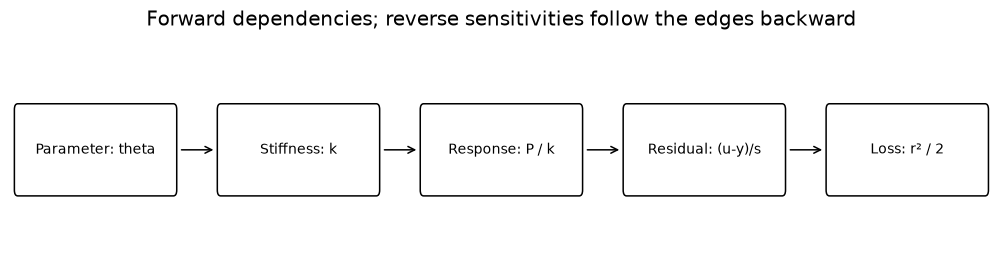

In [3]:
k_ref=2000.;y=.04;scale=.01;theta=.2

def spring_loss(theta):
 stiff=k_ref*np.exp(theta);response=P/stiff;residual=(response-y)/scale
 return .5*residual**2
stiff=k_ref*np.exp(theta);response=P/stiff;residual=(response-y)/scale
grad=residual*(1/scale)*(-P/stiff**2)*stiff
assert np.isclose(grad,-residual*response/scale)
h=1e-5;fd=(spring_loss(theta+h)-spring_loss(theta-h))/(2*h)
assert np.isclose(grad,fd,rtol=1e-7)
print('loss:',spring_loss(theta),'chain derivative:',grad,'finite difference:',fd)
RESULTS['spring_chain_gradient']=float(grad)
from matplotlib.patches import FancyBboxPatch
fig,ax=plt.subplots(figsize=(9,2.4));ax.axis('off')
labels=['Parameter: theta','Stiffness: k','Response: P / k','Residual: (u-y)/s','Loss: r² / 2']
for i,label in enumerate(labels):
 center=1+2.4*i
 ax.add_patch(FancyBboxPatch((center-.92,-.28),1.84,.56,boxstyle='round,pad=.04',fc='white',ec='black'))
 ax.text(center,0,label,ha='center',va='center',fontsize=9)
 if i<4:ax.annotate('',(center+1.43,0),(center+.98,0),arrowprops={'arrowstyle':'->'})
ax.set(xlim=(0,11.6),ylim=(-.8,.8),title='Forward dependencies; reverse sensitivities follow the edges backward');plt.show()


<a id="reverse-check"></a>
## A tiny neural computation, manual reverse pass

Two affine preactivations pass through tanh, then a weighted scalar output and squared-error loss. We differentiate with respect to the flattened weight matrix. The shared loss sensitivity passes backward through the output weights and tanh; an outer product supplies each weight derivative. This is reverse accumulation implemented explicitly, not a claim to provide a general autodiff engine. At a shared node, contributions from all outgoing routes must add.

**Predict:** what are the shapes of the preactivation, activation, weight gradient and full output Jacobian with respect to the four weights? Why can we check a scalar loss gradient without building all intermediate Jacobians?


In [4]:
x=np.array([.3,-.7]);W=np.array([[.2,.4],[-.3,.1]]);b=np.array([.1,-.2]);a=np.array([.7,-.5]);target=.25

def neural_loss(flat):
 activation=np.tanh(flat.reshape(2,2)@x+b);prediction=a@activation
 return .5*(prediction-target)**2
z=W@x+b;activation=np.tanh(z);prediction=a@activation
back_z=(prediction-target)*a*(1-activation**2)
grad_W=np.outer(back_z,x);flat=W.ravel();h=1e-5;numeric=[]
for j in range(len(flat)):
 step=np.eye(len(flat))[j]*h;numeric.append((neural_loss(flat+step)-neural_loss(flat-step))/(2*h))
assert np.allclose(grad_W.ravel(),numeric,rtol=1e-7,atol=1e-10)
direction_errors=[]
for _ in range(5):
 d=rng.normal(size=flat.size);d/=np.linalg.norm(d)
 numeric_direction=(neural_loss(flat+h*d)-neural_loss(flat-h*d))/(2*h)
 direction_errors.append(abs(numeric_direction-grad_W.ravel()@d))
assert max(direction_errors)<1e-9
print('Manual gradient:',grad_W,'maximum directional absolute error:',max(direction_errors))
RESULTS['max_directional_absolute_error']=float(max(direction_errors))


Manual gradient: [[-0.03332614  0.07776098]
 [ 0.02127093 -0.04963218]] maximum directional absolute error: 2.1797147420343777e-12


<a id="difference-sweep"></a>
## Shrinking the increment eventually hurts

Check exp(-theta) at theta=0.7 in float64 using a central difference. Its exact derivative is -exp(-theta). The central truncation error decreases quadratically at sufficiently large steps; floating subtraction dominates at tiny steps. The plot floors only displayed relative error to permit a log axis. The reported numeric values remain unfloored. There is no universal best h.

**Predict:** will h=1e-16 beat h=1e-5? Why should a dimensionful parameter use a reference scale rather than the same raw h as every other parameter?


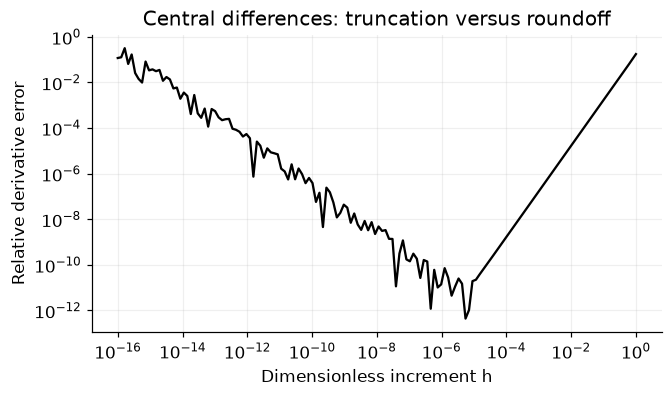

In [5]:
t=.7;truth=-np.exp(-t);hs=np.logspace(-16,0,150)
estimates=(np.exp(-(t+hs))-np.exp(-(t-hs)))/(2*hs)
relative_error=np.abs((estimates-truth)/truth)
fig,ax=plt.subplots(figsize=(6,3.5));ax.loglog(hs,np.maximum(relative_error,1e-17),'k-')
ax.set(xlabel='Dimensionless increment h',ylabel='Relative derivative error',title='Central differences: truncation versus roundoff');ax.grid(alpha=.2);plt.show()
assert relative_error[0]>relative_error[np.argmin(abs(hs-1e-5))]
RESULTS['best_observed_step']=float(hs[np.argmin(relative_error)]);RESULTS['minimum_relative_error']=float(relative_error.min());RESULTS['smallest_step_relative_error']=float(relative_error[0])


<a id="exercises"></a>
## Exercises and hints

1. Rewrite load in kN. Compute du/dP_kN and show that its product with a fixed physical load increment agrees with the SI calculation.
2. Differentiate the spring loss with respect to raw k instead of theta. Compare units and optimization geometry.
3. Change the nonlinear output to use an activation twice on two paths; add the two reverse contributions.
4. Check the force-direction sensitivity of the two-spring system by solving K*delta_u=d, without constructing K inverse.
5. Compare float32 and float64 finite-difference sweeps; explain why tighter tolerance is not always a better test.

**Hints:** derivative units follow output/input; exp(theta) contributes a factor k; branch contributions add, not multiply. A central difference across k=0 is invalid. Framework autodiff differentiates the program written and can faithfully propagate a broadcast mistake. At a nonsmooth threshold, declare a one-sided question rather than asserting a nonexistent two-sided derivative.

**Troubleshooting:** compare absolute and relative error together near a zero derivative; use multiple directions and admissible perturbations. [NumPy exponential](https://numpy.org/doc/stable/reference/generated/numpy.exp.html) documents the elementary operation; all derivative formulas here are explicitly derived and independently checked.


In [6]:
summary={'example_id':'code_009','seed':SEED,'versions':VERSIONS,
'hardware':platform.system()+' '+platform.machine()+' CPU',
'concepts_demonstrated':['derivative units', 'spring sensitivities', 'chain rule and dimensionless loss', 'manual reverse accumulation', 'coordinate and directional finite differences', 'step-size error tradeoff'],'results':RESULTS,
'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["derivative units", "spring sensitivities", "chain rule and dimensionless loss", "manual reverse accumulation", "coordinate and directional finite differences", "step-size error tradeoff"], "elapsed_seconds": 0.187, "example_id": "code_009", "hardware": "Darwin arm64 CPU", "results": {"best_observed_step": 5.47337284952015e-06, "du_dP_m_per_N": 0.0005, "du_dk_m2_per_N": -2.5e-05, "max_directional_absolute_error": 2.1797147420343777e-12, "minimum_relative_error": 4.373057800113602e-13, "smallest_step_relative_error": 0.11785731086748523, "spring_chain_gradient": -0.3833860893313437}, "seed": 202, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
